## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

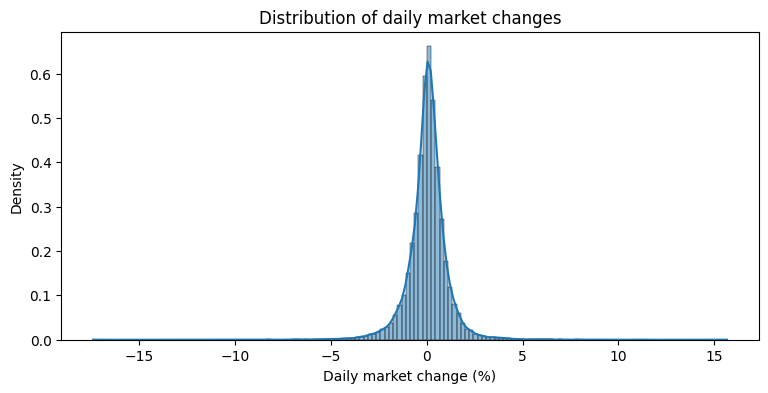

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

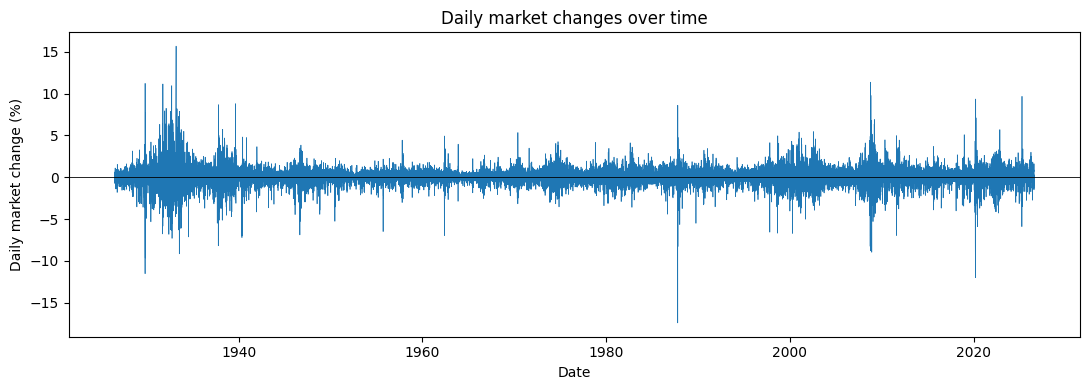

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [7]:
df['Today'] = np.where(df['market_return_pct'] > 0, 'Up', 'Down/Flat')

df['next'] = df['Today'].shift(-1)

pairs = df.dropna(subset = ['next'])


df['ret_today'] = df['market_return_pct']
df['ret_next'] = df['market_return_pct'].shift(-1)

joint = pd.crosstab(pairs['Today'], pairs['next'], normalize = 'all')
print("Joint PMF:\n", joint, "\n")


Joint PMF:
 next       Down/Flat        Up
Today                         
Down/Flat   0.224720  0.228142
Up          0.228142  0.318996 



In [8]:
p_today = joint.sum(axis = 1)
p_next = joint.sum(axis = 0)

print("Marginal of today:\n", p_today, "\n")
print("Marginal of next:\n", p_next, "\n")

Marginal of today:
 Today
Down/Flat    0.452862
Up           0.547138
dtype: float64 

Marginal of next:
 next
Down/Flat    0.452862
Up           0.547138
dtype: float64 



In [10]:
conditional = joint.div(p_today, axis=0)
print("Conditional PMF:\n", conditional)

print(conditional['Up'])

Conditional PMF:
 next       Down/Flat        Up
Today                         
Down/Flat   0.496221  0.503779
Up          0.416974  0.583026
Today
Down/Flat    0.503779
Up           0.583026
Name: Up, dtype: float64


Up days are more common overall than down/flat days. Based on the transition probabilities, an up day is more likely to occur after another up day rather than after a down/flat day, with up -> up having a transition probability of .583 and down/flat -> up having a probability of .504. 

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [12]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]

labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

df['state'] = pd.cut(df['market_return_pct'], bins = bins, labels = labels, right = True, ordered = True)
df['next_state'] = df['state'].shift(-1)


pairs = df.dropna(subset=['next_state']).copy() 

counts = df['state'].value_counts().reindex(labels)
print(counts)

state
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64


In [13]:
joint = pd.crosstab(pairs['state'], pairs['next_state'], normalize='all')
p_today = joint.sum(axis=1)
p_next  = joint.sum(axis=0)
print(joint.round(4), "\n", p_today.round(4), "\n", p_next.round(4))

next_state  Large loss  Small loss  Near zero  Small gain  Large gain
state                                                                
Large loss      0.0213      0.0272     0.0091      0.0278      0.0195
Small loss      0.0354      0.0886     0.0342      0.0978      0.0274
Near zero       0.0093      0.0420     0.0210      0.0493      0.0093
Small gain      0.0250      0.1001     0.0550      0.1594      0.0326
Large gain      0.0138      0.0255     0.0116      0.0378      0.0199 
 state
Large loss    0.1049
Small loss    0.2834
Near zero     0.1309
Small gain    0.3721
Large gain    0.1087
dtype: float64 
 next_state
Large loss    0.1049
Small loss    0.2834
Near zero     0.1308
Small gain    0.3721
Large gain    0.1087
dtype: float64


In [14]:
print(joint.stack().sort_values(ascending = False).head(5))

state       next_state
Small gain  Small gain    0.159422
            Small loss    0.100057
Small loss  Small gain    0.097775
            Small loss    0.088648
Small gain  Near zero     0.055029
dtype: float64


In [ ]:
cond = pd.crosstab(pairs['state'], pairs['next_state'], normalize = 'index')
print(cond)

for s in labels:
    print(s, "->", cond.loc[s].nlargest(2).to_dict())

    

next_state  Large loss  Small loss  Near zero  Small gain  Large gain
state                                                                
Large loss    0.203335    0.259152   0.086263    0.264951    0.186299
Small loss    0.125067    0.312802   0.120505    0.345008    0.096618
Near zero     0.071200    0.320837   0.160128    0.376925    0.070910
Small gain    0.067150    0.268908   0.147895    0.428455    0.087592
Large gain    0.127317    0.234697   0.107030    0.347674    0.183281
Large loss -> {'Small gain': 0.2649510692279812, 'Small loss': 0.25915186661834}
Small loss -> {'Small gain': 0.34500805152979064, 'Small loss': 0.31280193236714976}
Near zero -> {'Small gain': 0.37692531240918337, 'Small loss': 0.32083696599825634}
Small gain -> {'Small gain': 0.428454619787408, 'Small loss': 0.26890842191332787}
Large gain -> {'Small gain': 0.34767401189227004, 'Small loss': 0.2346974466596712}


In [16]:
summary = (pairs.groupby('state', observed=True)['ret_next']
                .describe()
                .reindex(labels))
print(summary.round(3))

             count   mean    std    min   25%   50%   75%    max
state                                                           
Large loss  2759.0 -0.038  1.721 -17.41 -0.79 -0.01  0.72  11.22
Small loss  7452.0 -0.044  1.010 -11.23 -0.53  0.01  0.45  11.36
Near zero   3441.0  0.015  0.826  -8.19 -0.35  0.03  0.42   5.49
Small gain  9784.0  0.107  0.832  -8.25 -0.25  0.12  0.50   8.67
Large gain  2859.0  0.163  1.384 -12.00 -0.37  0.15  0.73  15.67


The most common types of days are small gains and small losses with 9785 and 7452 days of each respectively. The least common are large gain and large loss with each having a bit under 3000 days. The transitions that are the most likely to occur are small gain -> small gain with a .159 transition probability, and small gain -> small loss with a transition probability of .1. For every state, the two most likely next states are small gain and then small loss. Overall though, the transition probabilities are all fairly similar to each other so it is definitely quite difficult to predict the next state. 

The expectations for the days following losses are negative and positive for the days folliwing gains. This indicates that losses and gains carry momentum with them, although the actual mean changes are fairly small. However, large gains and losses have much higher standard deviations for the next day's price, meaning that there is increased volatility in the market following a large gain or loss. Additionally, the value ranges following large gains and losses are much greater than after small gains or losses. 

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

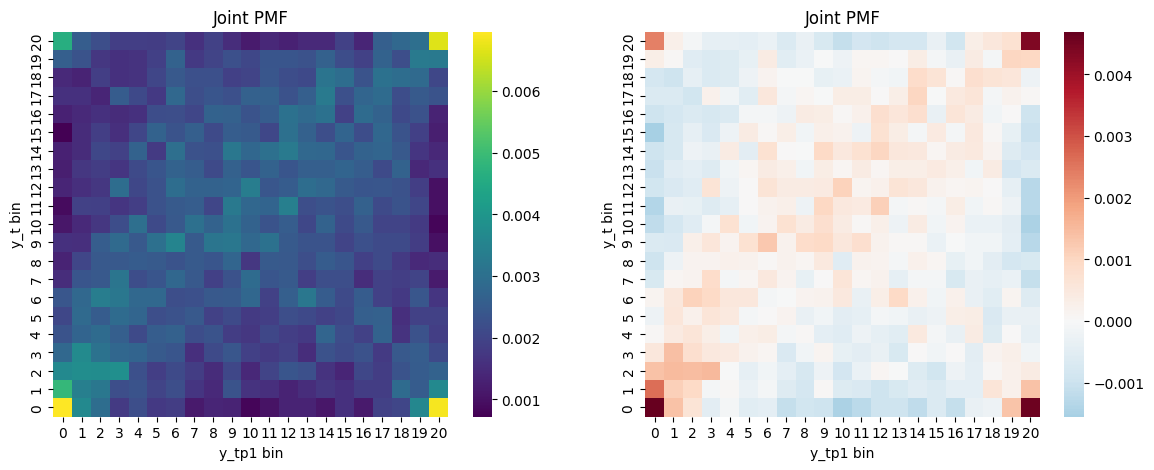

In [19]:
df['y_t']   = pd.qcut(df['market_return_pct'], q=21, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)
df['ret_tp1'] = df['market_return_pct'].shift(-1)

pairs = df.dropna(subset=['y_tp1']).copy()
pairs['y_tp1'] = pairs['y_tp1'].astype(int) 

joint = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize='all')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(joint, ax=ax[0], cmap='viridis')
ax[0].set_title('Joint PMF')
sns.heatmap(joint - 1/21**2, ax=ax[1], cmap='RdBu_r', center=0)
ax[1].set_title('Joint PMF')
for a in ax:
    a.invert_yaxis(); a.set_xlabel('y_tp1 bin'); a.set_ylabel('y_t bin')
plt.show()

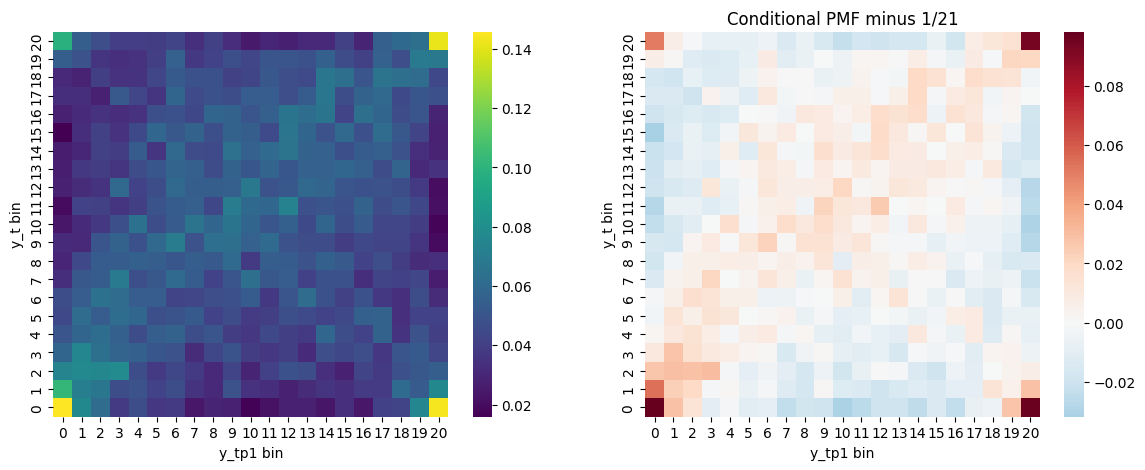

In [22]:
cond = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize='index')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cond, ax=ax[0], cmap='viridis')
sns.heatmap(cond - 1/21, ax=ax[1], cmap='RdBu_r', center=0)
ax[1].set_title('Conditional PMF minus 1/21')
for a in ax:
    a.invert_yaxis(); a.set_xlabel('y_tp1 bin'); a.set_ylabel('y_t bin')
plt.show()

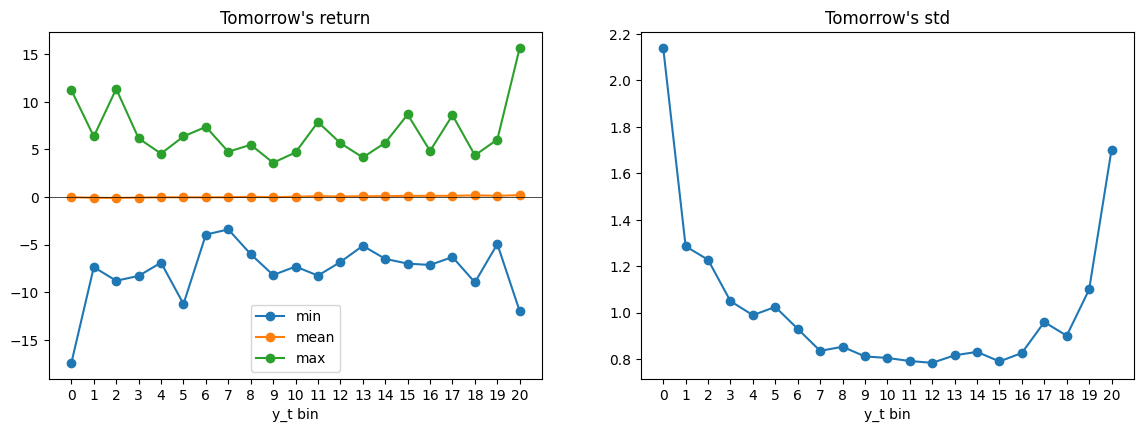

In [24]:
stats = pairs.groupby('y_t')['ret_tp1'].agg(['min', 'mean', 'max', 'std'])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
stats[['min', 'mean', 'max']].plot(ax=ax[0], marker='o')
ax[0].axhline(0, color='k', lw=0.5)
ax[0].set_title("Tomorrow's return")
stats['std'].plot(ax=ax[1], marker='o')
ax[1].set_title("Tomorrow's std")
for a in ax:
    a.set_xlabel('y_t bin'); a.set_xticks(range(21))
plt.show()

Overall, direction seems very hard to predict. The conditional PMF deviates from uniform by only a small amount (on the order of a percentage point on a baseline of 4.8%), and the conditional mean of tomorrow’s return moves by a tenth of a percent or so against a std near 1, so any directional edge is tiny. However, volatility does seem to be easier to predict, as today’s bin tells us a lot about the size of tomorrow’s move, as the U-shaped std and the corner patterns in the heatmaps show. So risk can be forecasted fairly well, but not returns. A small statistical edge in direction would also be hard to turn into profit after transaction costs.